# Analysis of Stock Price Behavior Using Monte Carlo Simulation: A Case Study of Apple, Google, and Microsoft (2020–2024)

## 1. Descriptive Analysis

In [36]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

In [37]:
# downloading  of five-years data (2020-2025) for 3 compenies

tickers = [ 'AAPL', 'GOOGL', 'MSFT']
data = yf.download(tickers, start='2020-01-01', end='2025-01-01')

[*********************100%***********************]  3 of 3 completed


In [38]:
# display of the first 5 rows

data.head()

Price           Close                              High             \
Ticker           AAPL      GOOGL        MSFT       AAPL      GOOGL   
Date                                                                 
2020-01-02  72.271538  67.788948  151.544266  72.331694  67.788948   
2020-01-03  71.568924  67.434319  149.657288  72.326889  68.040058   
2020-01-06  72.139191  69.231697  150.044098  72.177691  69.256954   
2020-01-07  71.799934  69.097992  148.676071  72.403897  69.513540   
2020-01-08  72.954918  69.589806  151.044189  73.255698  69.927096   

Price                         Low                              Open  \
Ticker            MSFT       AAPL      GOOGL        MSFT       AAPL   
Date                                                                  
2020-01-02  151.648051  71.029915  66.689909  149.383667  71.282568   
2020-01-03  150.912139  71.345145  66.731012  149.128932  71.501549   
2020-01-06  150.110150  70.442792  66.913259  147.666485  70.693043   
2020-01-07  150.647974  71.580965  68.922167  148.430767  72.148835   
2020-01-08  151.714078  71.503953  68.975156  149.025110  71.503953   

Price                                 Volume                      
Ticker          GOOGL        MSFT       AAPL     GOOGL      MSFT  
Date                                                              
2020-01-02  66.785005  149.808237  135480400  27278000  22622100  
2020-01-03  66.764696  149.374250  146322800  23408000  21116200  
2020-01-06  66.944457  148.204284  118387200  46768000  20813700  
2020-01-07  69.362972  150.317759  108872000  34330000  21634100  
2020-01-08  69.083621  149.949731  132079200  35314000  27746500

In [39]:
# saving data in CSV file

data.to_csv('stock_data.csv')

In [40]:
# ***
#display the number of rows & columns

print(data.shape)

(1258, 15)


In [41]:
# checking the existence of blank data (Missing Values)

print(data.isnull().sum())

Price   Ticker
Close   AAPL      0
        GOOGL     0
        MSFT      0
High    AAPL      0
        GOOGL     0
        MSFT      0
Low     AAPL      0
        GOOGL     0
        MSFT      0
Open    AAPL      0
        GOOGL     0
        MSFT      0
Volume  AAPL      0
        GOOGL     0
        MSFT      0
dtype: int64


In [42]:
# calculating daily returns for each company's closing price

returns = data['Close'].pct_change()
returns.head()

Ticker,AAPL,GOOGL,MSFT
Date,,,
2020-01-02,NaN,NaN,NaN
2020-01-03,-0.009722,-0.005231,-0.012452
2020-01-06,0.007968,0.026654,0.002585
2020-01-07,-0.004703,-0.001931,-0.009117
2020-01-08,0.016086,0.007118,0.015928


In [43]:
# drop the first row

returns = returns.dropna()

In [44]:
# Mean
# average daily returns of each company

mean_returns = returns.mean()
print("Average Daily Returns: ")
print(mean_returns)


# Standard deviation
# standard deviatin (volatility) of each company's daily returns

std_returns = returns.std()
print("\nStandard Deviation (Volatility): ")
print(std_returns)


Average Daily Returns: 
Ticker
AAPL     0.001182
GOOGL    0.001022
MSFT     0.000988
dtype: float64

Standard Deviation (Volatility): 
Ticker
AAPL     0.019956
GOOGL    0.020472
MSFT     0.019211
dtype: float64


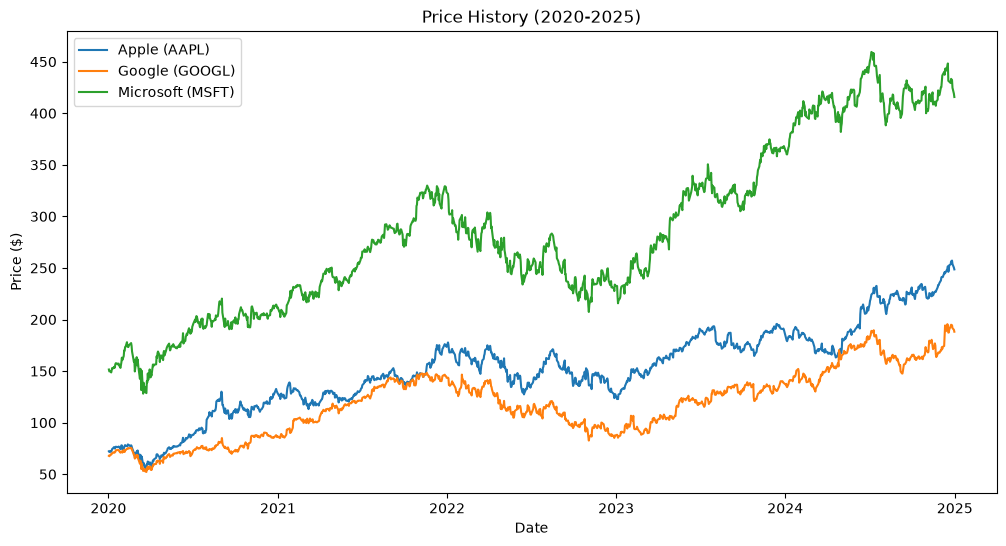

In [45]:
# plot the closing price chart of all 3 companies

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(data['Close']['AAPL'], label='Apple (AAPL)')
plt.plot(data['Close']['GOOGL'], label='Google (GOOGL)')
plt.plot(data['Close']['MSFT'], label='Microsoft (MSFT)')

plt.title('Price History (2020-2025)')

plt.xlabel('Date')

plt.ylabel('Price ($)')

plt.legend()

plt.show()

In [46]:
# displaying the mean & standard deviation in a table

summary = pd.DataFrame({'Mean': mean_returns, 'Std': std_returns})
print(summary)

            Mean       Std
Ticker                    
AAPL    0.001182  0.019956
GOOGL   0.001022  0.020472
MSFT    0.000988  0.019211


## 2. Correlation Analysis

In [54]:
# calculating the correlation matrix between the daily returns of 3 companies

correlation_matrix = returns.corr()
print(correlation_matrix)

Ticker      AAPL     GOOGL      MSFT
Ticker                              
AAPL    1.000000  0.648932  0.748327
GOOGL   0.648932  1.000000  0.746182
MSFT    0.748327  0.746182  1.000000


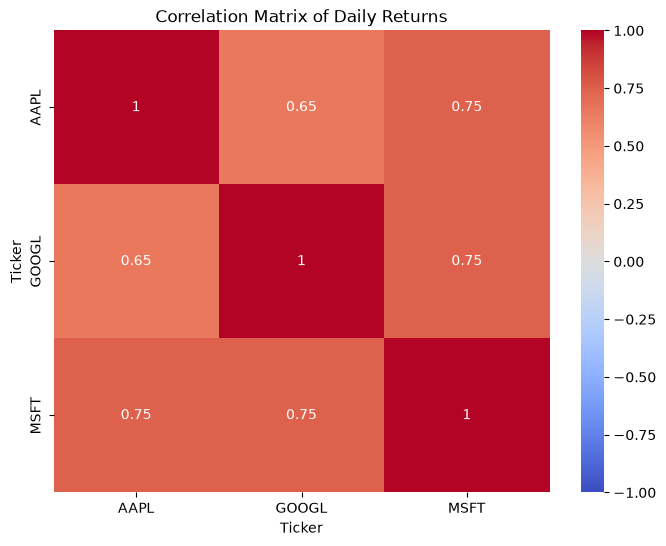

In [48]:
# drawing a correlation heatmap

import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)

plt.title('Correlation Matrix of Daily Returns')

plt.show()

## 3. Mont Carlo Simulation

In [49]:
# choosing the time horizon and number of simulations

#simulation settings
days = 252  # the number of woring days in a year
simulations = 1000  #the number of random paths
last_price = data['Close'].iloc[-1]  #the latest price of each company

In [ ]:
# IT IS NOT ESSENTIAL
# to ensure reproducibility of the simulation results
np.random.seed(42)

In [ ]:
# simulation code

import numpy as np
# mean & standard deviation of daily returns (previously calculated)
mu = mean_returns.values
sigma = std_returns.values

# simulating future prices for each company
simulated_prices = np.zeros((days, simulations, len(tickers)))  # genrating an array to store the results

for i in range(len(tickers)):
    # generating random pathes or each company
    random_shocks = np.random.normal(mu[i], sigma[i], (days, simulations))  # generating random shocks
    price_paths = last_price[i] * np.exp(np.cumsum(random_shocks, axis=0,))  # calculating price paths - using Geometric Brownian motion formula
    simulated_prices[:, :, i] = price_paths  # storing the results

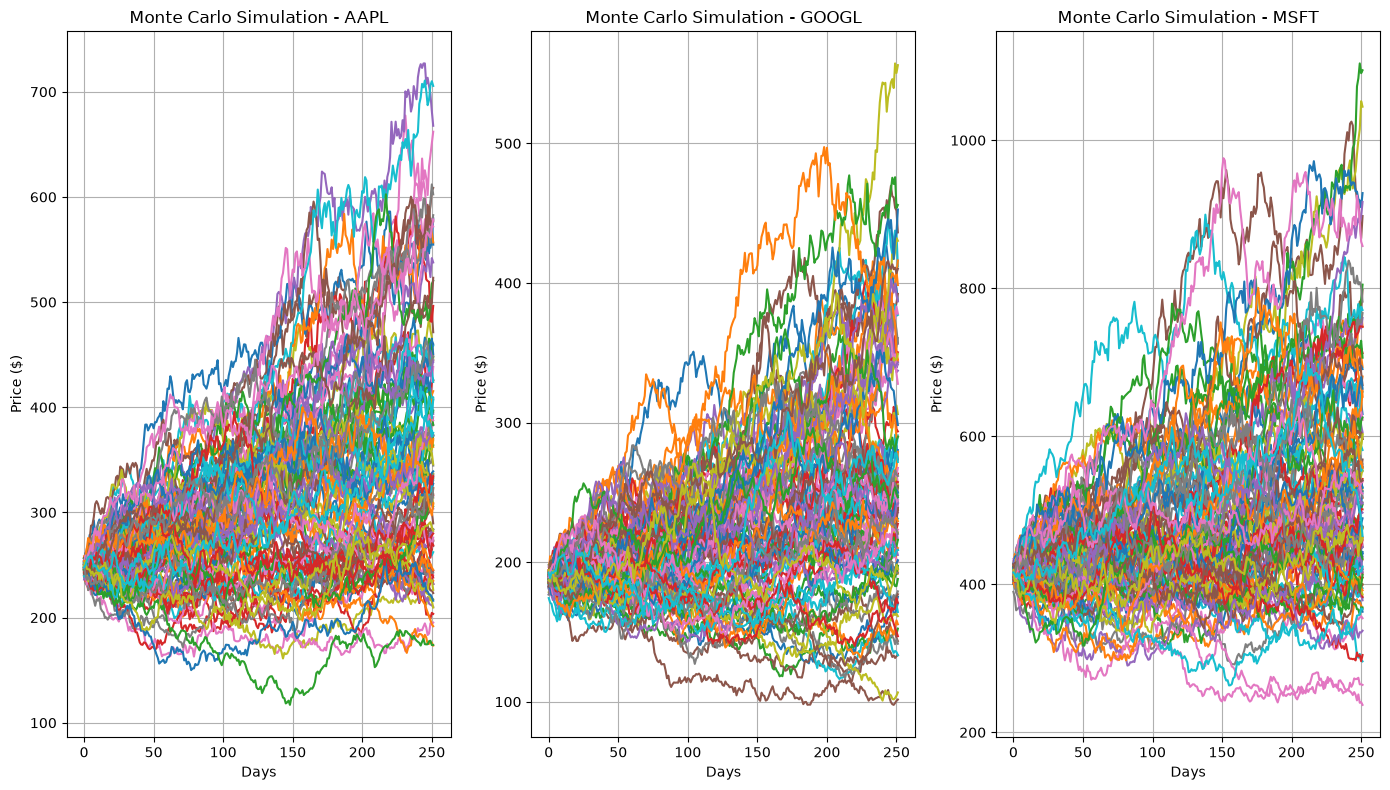

In [58]:
# plot 100 random paths for each company
plt.figure(figsize=(14, 8))

for i in range(len(tickers)):
    plt.subplot(1, 3, i+1) # plotting the diagram in subsection
    plt.plot(simulated_prices[:, :, i] [:, :100]) # drawing the lines of prices - only the first 100 paths
    plt.title(f'Monte Carlo Simulation - {tickers[i]}')
    plt.xlabel('Days')
    plt.ylabel('Price ($)')
    plt.grid(True)  # grid lines

plt.tight_layout()  # adjust the spacing between charts
plt.show()

In [59]:
# calculating expected value and risk

# calculating the expected final price and final returns
final_prices = simulated_prices[-1, :, :]  # prices in the last day
expected_return = (final_prices.mean(axis=0) / last_price) - 1  # last_price = current price --- Expected Return = (Average Final Price / Last Price) - 1
risk = final_prices.std(axis=0) / last_price  # risk (price fluctuation) --- last price = current price --- Risk = Standard Deviation of Final Price / Last price

print('Expected Final Price: ')
print(expected_return)
print('\nRisk (Standard Deviation of Return): ')
print(risk)

Expected Final Price: 
Ticker
AAPL     0.418303
GOOGL    0.346190
MSFT     0.343350
Name: 2024-12-31 00:00:00, dtype: float64

Risk (Standard Deviation of Return): 
Ticker
AAPL     0.464365
GOOGL    0.447580
MSFT     0.410374
Name: 2024-12-31 00:00:00, dtype: float64
